<a href="https://colab.research.google.com/github/divithashree/MLA0201/blob/main/Find_S_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Dataset:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes


FIND-S Learning Process:
------------------------------------------------------------
Example 1:
Hypothesis = ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
Example 2:
Hypothesis = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Example 3:
Hypothesis = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Example 4:
Hypothesis = ['Sunny', 'Warm', '?', 'Strong', '?', '?']


FINAL MOST SPECIFIC HYPOTHESIS
Sky: Sunny
AirTemp: Warm
Humidity: ?
Wind: Strong
Water: ?
Forecast: ?


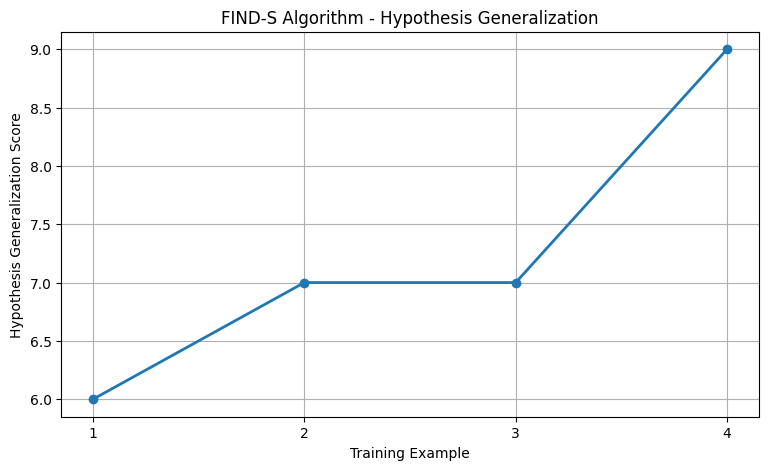

In [ ]:
# ============================================
# FIND-S ALGORITHM
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Step 1: Create Training Dataset
# --------------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)
print("\n")


# --------------------------------------------
# Step 2: FIND-S Algorithm
# --------------------------------------------

def find_s(dataframe):
    attributes = list(dataframe.columns[:-1])
    target = dataframe.columns[-1]

    # Initialize hypothesis with most specific values
    hypothesis = ['ϕ'] * len(attributes)

    hypothesis_history = []

    print("FIND-S Learning Process:")
    print("-" * 60)

    for index, row in dataframe.iterrows():

        # Consider only positive examples
        if row[target] == 'Yes':

            for i, attribute in enumerate(attributes):

                # First positive example
                if hypothesis[i] == 'ϕ':
                    hypothesis[i] = row[attribute]

                # Generalize if values are different
                elif hypothesis[i] != row[attribute]:
                    hypothesis[i] = '?'

        hypothesis_history.append(hypothesis.copy())

        print(f"Example {index + 1}:")
        print("Hypothesis =", hypothesis)

    return hypothesis, hypothesis_history


# --------------------------------------------
# Step 3: Run FIND-S
# --------------------------------------------

final_hypothesis, history = find_s(df)


# --------------------------------------------
# Step 4: Display Final Hypothesis
# --------------------------------------------

print("\n")
print("=" * 60)
print("FINAL MOST SPECIFIC HYPOTHESIS")
print("=" * 60)

for attribute, value in zip(df.columns[:-1], final_hypothesis):
    print(f"{attribute}: {value}")


# --------------------------------------------
# Step 5: Prepare Data for Graph
# --------------------------------------------

# Convert hypothesis values into numerical values
# ϕ = 0, specific value = 1, ? = 2

def hypothesis_score(h):
    score = 0

    for value in h:
        if value == 'ϕ':
            score += 0
        elif value == '?':
            score += 2
        else:
            score += 1

    return score


scores = [hypothesis_score(h) for h in history]
examples = list(range(1, len(scores) + 1))


# --------------------------------------------
# Step 6: Matplotlib Graph
# --------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    examples,
    scores,
    marker='o',
    linewidth=2
)

plt.title("FIND-S Algorithm - Hypothesis Generalization")
plt.xlabel("Training Example")
plt.ylabel("Hypothesis Generalization Score")

plt.xticks(examples)
plt.grid(True)

plt.show()